## Лабораторная № 4
#### Часть 1. Работа с наборами данных и постановка задачи
Для работы выбраны два набора данных для задачи бинарной классификации:
* Датасет №1: Pima Indians Diabetes (медицинская диагностика).
* Датасет №2: Churn Modelling (отток клиентов банка).

Для каждого набора выполняется предобработка (пропуски, кодирование категориальных признаков, масштабирование `StandardScaler`) и разбиение на обучающую и тестовую выборки с сохранением пропорций классов (`stratify`).

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_theme(style="whitegrid")

### Датасет №1. Pima Indians Diabetes

* **Бизнес-задача:** определить, есть ли у пациента диабет.
* **Объект:** пациент.
* **Признаки:** медицинские показатели (глюкоза, давление, инсулин, BMI, возраст и др.).
* **Целевая переменная:** наличие диабета (`0` — нет, `1` — есть).

In [23]:
path1 = kagglehub.dataset_download("jameshramos/pima-indians-diabetes")

csv_file1 = [f for f in os.listdir(path1) if f.endswith('.csv')][0]
df1 = pd.read_csv(os.path.join(path1, csv_file1))

print("Первые 5 строк датасета")
display(df1.head())

print("\nИнформация о типах и пропусках")
df1.info()

Первые 5 строк датасета


,times_pregnant,glucose_concentration,diastolic_blood_pressure,triceps_sf_thickness,serum_insulin,bmi,d_pedigree_function,years_of_age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   times_pregnant            768 non-null    int64  
 1   glucose_concentration     768 non-null    int64  
 2   diastolic_blood_pressure  768 non-null    int64  
 3   triceps_sf_thickness      768 non-null    int64  
 4   serum_insulin             768 non-null    int64  
 5   bmi                       768 non-null    float64
 6   d_pedigree_function       768 non-null    float64
 7   years_of_age              768 non-null    int64  
 8   diabetes                  768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.2 KB


### Предобработка и разделение выборки (Датасет №1)

В медицинских признаках (глюкоза, давление, толщина кожной складки, инсулин, BMI) значение `0` невозможно, поэтому такие нули считаем пропусками. Разделяем выборку на обучающую ($80\%$) и тестовую ($20\%$) со `stratify`, после чего заполняем пропуски медианой и масштабируем признаки (параметры считаются по обучающей выборке).

In [24]:
class_names1 = ['Нет диабета', 'Диабет']

# нули в этих признаках означают пропуски
zero_cols = ['glucose_concentration', 'diastolic_blood_pressure', 'triceps_sf_thickness', 'serum_insulin', 'bmi']
df1[zero_cols] = df1[zero_cols].replace(0, np.nan)

X1 = df1.drop(columns='diabetes')
y1 = df1['diabetes']

X_train1, X_test1, y_train1, y_test1 = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

imputer1 = SimpleImputer(strategy='median')
X_train1 = imputer1.fit_transform(X_train1)
X_test1 = imputer1.transform(X_test1)

scaler1 = StandardScaler()
X_train1 = scaler1.fit_transform(X_train1)
X_test1 = scaler1.transform(X_test1)

print("Train:", X_train1.shape, "Test:", X_test1.shape)
print("Доля класса 1 в train:", round(y_train1.mean(), 3), "| в test:", round(y_test1.mean(), 3))

Train: (614, 8) Test: (154, 8)
Доля класса 1 в train: 0.349 | в test: 0.351


### Датасет №2. Bank Customer Churn

* **Бизнес-задача:** определить, уйдёт ли клиент из банка.
* **Объект:** клиент банка.
* **Признаки:** кредитный рейтинг, страна, пол, возраст, стаж, баланс, число продуктов и др.
* **Целевая переменная:** `Exited` (`0` — клиент остался, `1` — ушёл).

In [25]:
path2 = kagglehub.dataset_download("shrutimechlearn/churn-modelling")

csv_file2 = [f for f in os.listdir(path2) if f.endswith('.csv')][0]
df2 = pd.read_csv(os.path.join(path2, csv_file2))

print("Первые 5 строк датасета")
display(df2.head())

print("\nИнформация о типах и пропусках")
df2.info()

Первые 5 строк датасета


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Информация о типах и пропусках
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


### Предобработка и разделение выборки (Датасет №2)

Удаляем неинформативные столбцы (`RowNumber`, `CustomerId`, `Surname`), кодируем категориальные признаки (`Geography`, `Gender`) через `get_dummies`, разделяем выборку со `stratify` и масштабируем признаки. Пропусков в данных нет.

In [26]:
class_names2 = ['Остался', 'Ушёл']

df2 = df2.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
df2 = pd.get_dummies(df2, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

X2 = df2.drop(columns='Exited')
y2 = df2['Exited']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

scaler2 = StandardScaler()
X_train2 = scaler2.fit_transform(X_train2)
X_test2 = scaler2.transform(X_test2)

print("Train:", X_train2.shape, "Test:", X_test2.shape)
print("Доля класса 1 в train:", round(y_train2.mean(), 3), "| в test:", round(y_test2.mean(), 3))

Train: (8000, 11) Test: (2000, 11)
Доля класса 1 в train: 0.204 | в test: 0.204


## Часть 2. Программа моделирования и оптимизации
#### Базовая реализация методов классификации

Обучаем четыре алгоритма (kNN, Decision Tree, SVM, MLP) с параметрами по умолчанию и смотрим accuracy на тестовой выборке.

In [27]:
def get_models():
    return {
        'kNN': KNeighborsClassifier(),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'SVM': SVC(),
        'MLP': MLPClassifier(max_iter=1000, random_state=42)
    }

for title, (X_tr, X_te, y_tr, y_te) in {
    'Датасет №1': (X_train1, X_test1, y_train1, y_test1),
    'Датасет №2': (X_train2, X_test2, y_train2, y_test2)
}.items():
    print(title)
    for name, model in get_models().items():
        model.fit(X_tr, y_tr)
        print(f"  {name}: accuracy = {accuracy_score(y_te, model.predict(X_te)):.4f}")

Датасет №1
  kNN: accuracy = 0.7532
  Decision Tree: accuracy = 0.6818
  SVM: accuracy = 0.7403
  MLP: accuracy = 0.7403
Датасет №2
  kNN: accuracy = 0.8240
  Decision Tree: accuracy = 0.7825
  SVM: accuracy = 0.8610
  MLP: accuracy = 0.8605


#### Оптимизация и подбор гиперпараметров

Для каждого алгоритма подбираем ключевые гиперпараметры с помощью `GridSearchCV` (5-fold кросс-валидация):
* **kNN:** количество соседей;
* **Decision Tree:** глубина дерева;
* **SVM:** тип ядра и параметр регуляризации `C`;
* **MLP:** архитектура слоёв и функция активации.

In [28]:
param_grids = {
    # kNN: n_neighbors - число ближайших соседей, по которым голосуют за класс объекта
    #      (мало соседей - модель чувствительна к шуму, много - граница слишком сглаженная)
    'kNN': {'n_neighbors': [3, 5, 7, 9, 11]},

    # Decision Tree: max_depth - максимальная глубина дерева (число уровней разбиений)
    #      (мелкое дерево - недообучение, глубокое - переобучение; None - глубина не ограничена)
    'Decision Tree': {'max_depth': [3, 5, 10, None]},

    # SVM: C - сила регуляризации (малое C - гладкая граница, допускает ошибки;
    #      большое C - штрафует каждую ошибку, риск переобучения)
    #      kernel - тип границы: 'linear' - прямая, 'rbf' - искривлённая граница
    'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},

    # MLP: hidden_layer_sizes - архитектура: сколько скрытых слоёв и нейронов в каждом
    #      ((50,) - один слой на 50 нейронов, (50, 50) - два слоя по 50)
    #      activation - функция активации нейрона: 'relu' обнуляет отрицательные значения,
    #      'tanh' сжимает значения в диапазон от -1 до 1
    'MLP': {'hidden_layer_sizes': [(50,), (100,), (50, 50)], 'activation': ['relu', 'tanh']}
}

def tune_models(X_train, y_train):
    grids = {}    # сюда сохраняем результат подбора для каждого алгоритма
    for name, model in get_models().items():
        # перебор сетки: 5-fold кросс-валидация на train, лучшая комбинация выбирается по accuracy
        grid = GridSearchCV(model, param_grids[name], cv=5, scoring='accuracy', n_jobs=-1)
        grid.fit(X_train, y_train)
        grids[name] = grid
        # лучшие параметры и средняя accuracy этой комбинации на кросс-валидации
        print(f"{name}: {grid.best_params_} (CV accuracy = {grid.best_score_:.4f})")
    return grids

print("Датасет №1")
grids1 = tune_models(X_train1, y_train1)

print("\nДатасет №2")
grids2 = tune_models(X_train2, y_train2)

Датасет №1
kNN: {'n_neighbors': 11} (CV accuracy = 0.7639)
Decision Tree: {'max_depth': 3} (CV accuracy = 0.7428)
SVM: {'C': 0.1, 'kernel': 'linear'} (CV accuracy = 0.7737)
MLP: {'activation': 'relu', 'hidden_layer_sizes': (50,)} (CV accuracy = 0.7558)

Датасет №2
kNN: {'n_neighbors': 9} (CV accuracy = 0.8318)
Decision Tree: {'max_depth': 5} (CV accuracy = 0.8510)
SVM: {'C': 1, 'kernel': 'rbf'} (CV accuracy = 0.8548)
MLP: {'activation': 'relu', 'hidden_layer_sizes': (50,)} (CV accuracy = 0.8504)


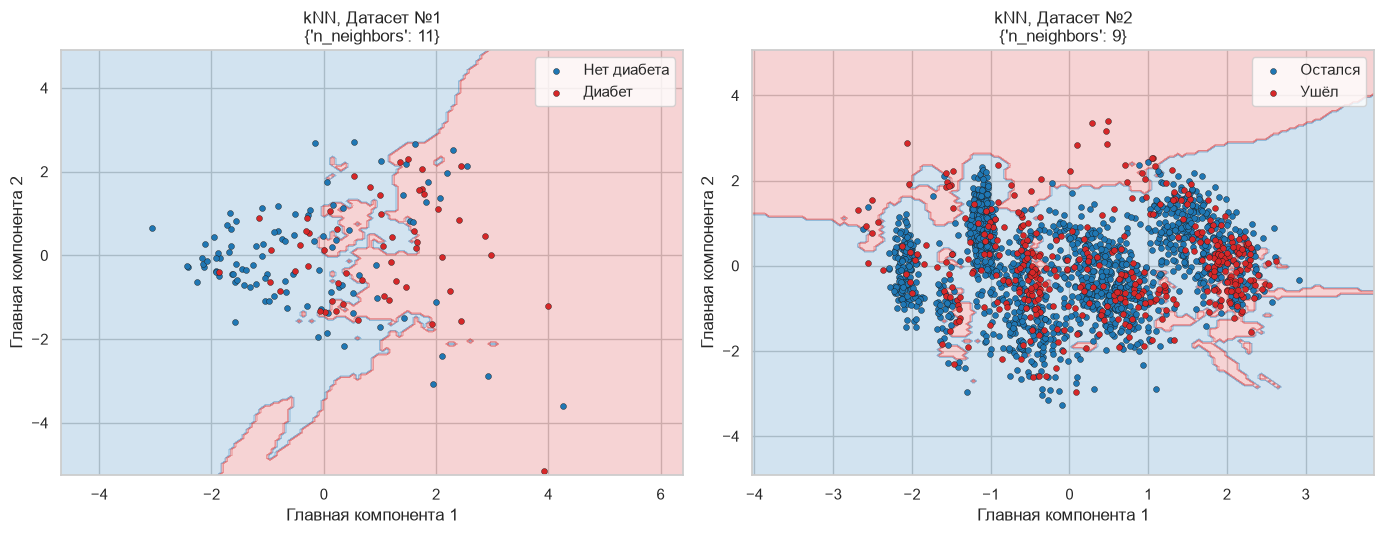

In [29]:
# kNN: граница решений (признаки сжаты до 2 главных компонент, модель переобучена с лучшими параметрами)
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

colors = ['tab:blue', 'tab:red']    # цвет класса 0 и класса 1

def plot_boundary(ax, grid, X_train, y_train, X_test, y_test, class_names, title):
    # сжимаем признаки до 2 главных компонент (PCA обучаем только по train)
    pca = PCA(n_components=2, random_state=42)
    X_train_2d = pca.fit_transform(X_train)
    X_test_2d = pca.transform(X_test)

    # копия лучшей модели (те же параметры), обученная на 2 компонентах
    model = clone(grid.best_estimator_).fit(X_train_2d, y_train)

    # закрашиваем области классов: для каждой точки плоскости модель предсказывает класс
    DecisionBoundaryDisplay.from_estimator(model, X_train_2d, ax=ax, cmap=ListedColormap(colors),
                                           alpha=0.2, response_method='predict', grid_resolution=150)

    # рисуем объекты тестовой выборки: отдельно каждый класс своим цветом
    for cls, label in enumerate(class_names):
        mask = np.asarray(y_test) == cls    # True там, где объект принадлежит классу cls
        ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1], color=colors[cls], label=label,
                   edgecolor='k', linewidth=0.3, s=18)

    # оформление: заголовок с лучшими параметрами, подписи осей, легенда
    ax.set_title(f"{title}\n{grid.best_params_}")
    ax.set_xlabel('Главная компонента 1')
    ax.set_ylabel('Главная компонента 2')
    ax.legend()

# два графика рядом: слева датасет №1, справа датасет №2
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_boundary(axes[0], grids1['kNN'], X_train1, y_train1, X_test1, y_test1, class_names1, 'kNN, Датасет №1')
plot_boundary(axes[1], grids2['kNN'], X_train2, y_train2, X_test2, y_test2, class_names2, 'kNN, Датасет №2')
plt.tight_layout()
plt.show()

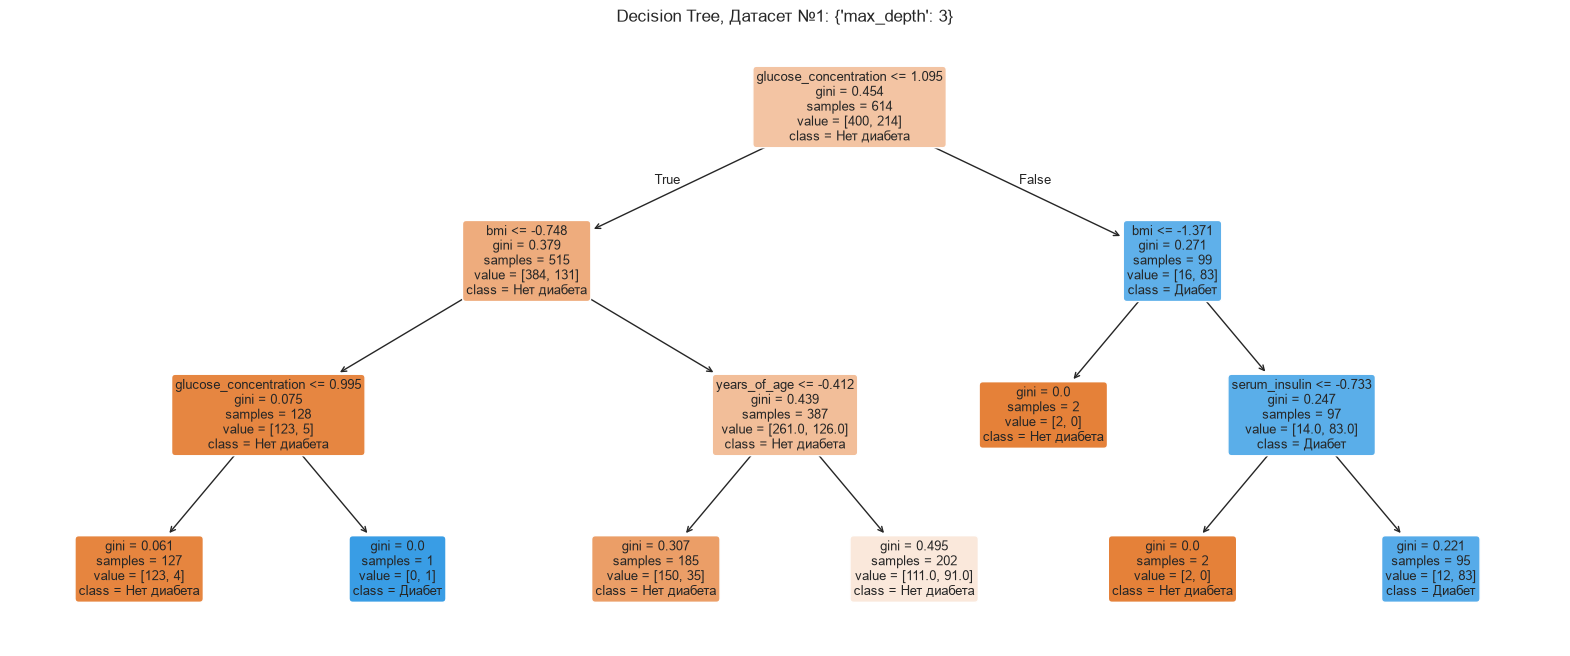

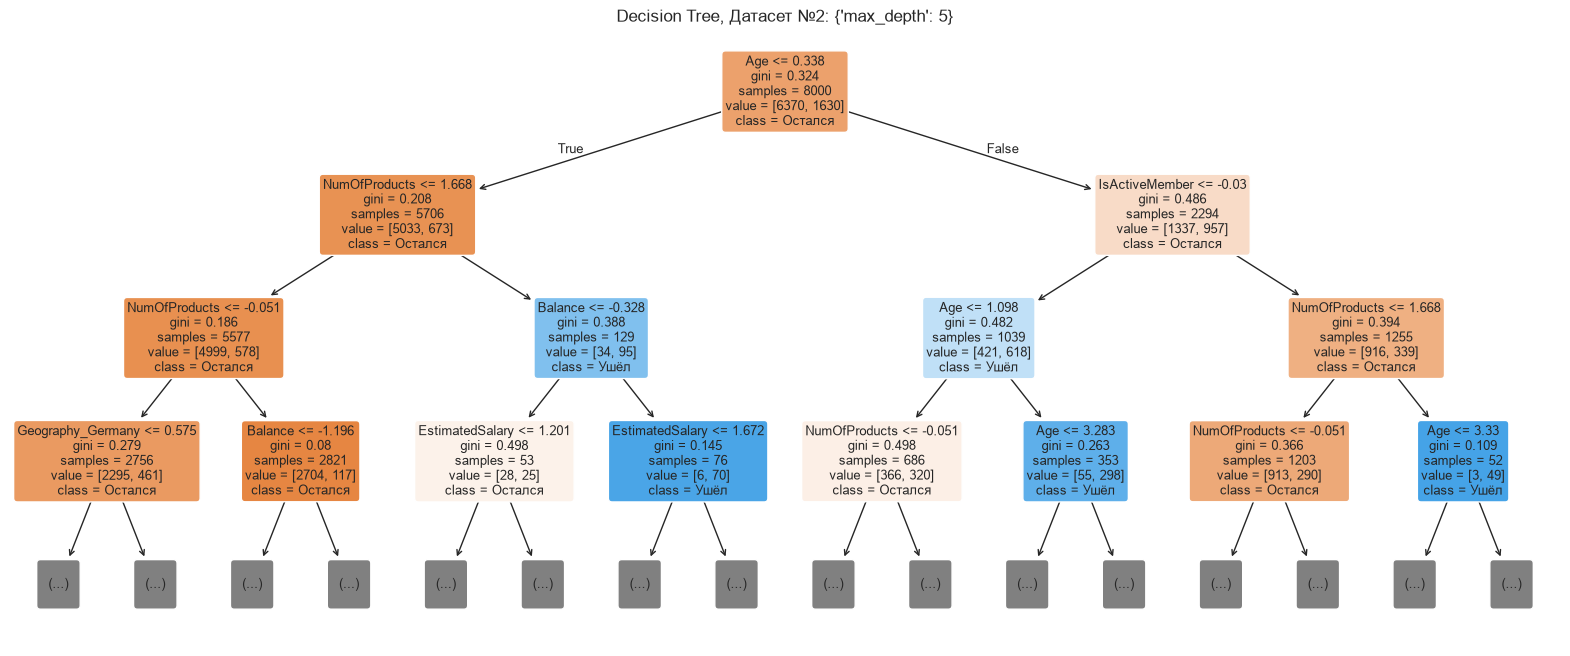

In [30]:
# Decision Tree: построенное дерево с лучшей глубиной (показаны верхние 3 уровня)
from sklearn.tree import plot_tree

# для каждого датасета берём: результат подбора, названия признаков, подписи классов, заголовок
for grid, names, cls, title in [(grids1['Decision Tree'], X1.columns, class_names1, 'Датасет №1'),
                                (grids2['Decision Tree'], X2.columns, class_names2, 'Датасет №2')]:
    plt.figure(figsize=(20, 8))   

    # рисуем лучшее дерево (обученное на всех признаках); max_depth=3 - показать только верхние уровни
    plot_tree(grid.best_estimator_, max_depth=3, feature_names=list(names), class_names=cls,
              filled=True,     # цвет узла зависит от преобладающего класса
              rounded=True,    # скруглённые углы узлов
              fontsize=9)

    plt.title(f"Decision Tree, {title}: {grid.best_params_}")    # заголовок с лучшими параметрами
    plt.show()

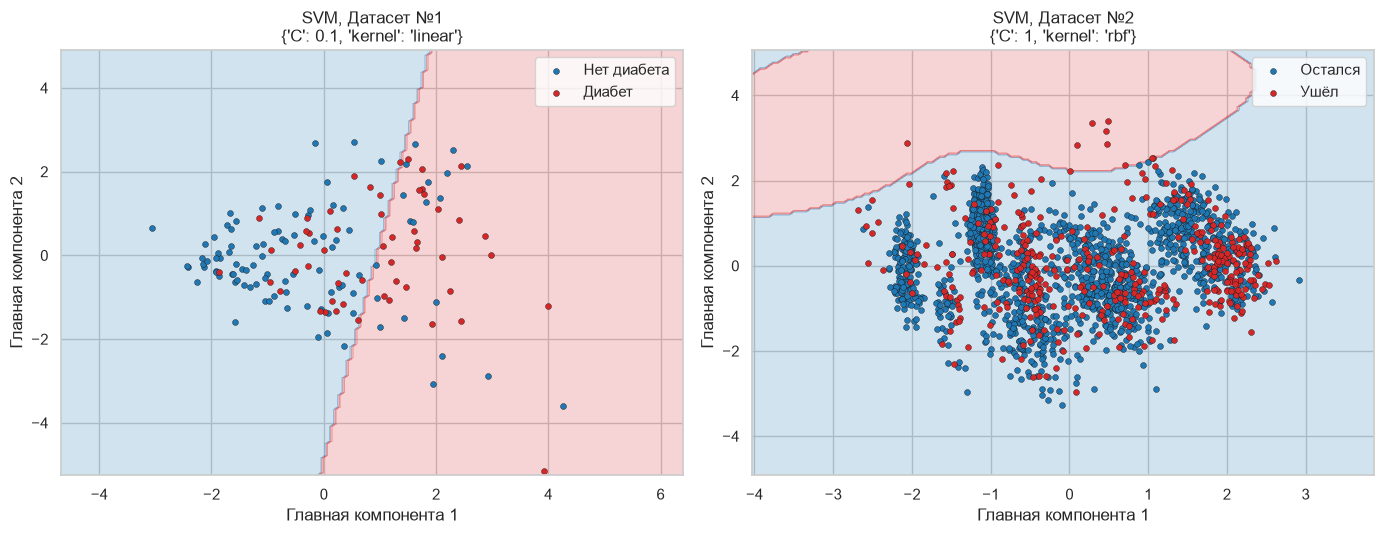

In [31]:
# SVM: граница решений с лучшими параметрами (функция plot_boundary из ячейки kNN)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_boundary(axes[0], grids1['SVM'], X_train1, y_train1, X_test1, y_test1, class_names1, 'SVM, Датасет №1')
plot_boundary(axes[1], grids2['SVM'], X_train2, y_train2, X_test2, y_test2, class_names2, 'SVM, Датасет №2')
plt.tight_layout()
plt.show()

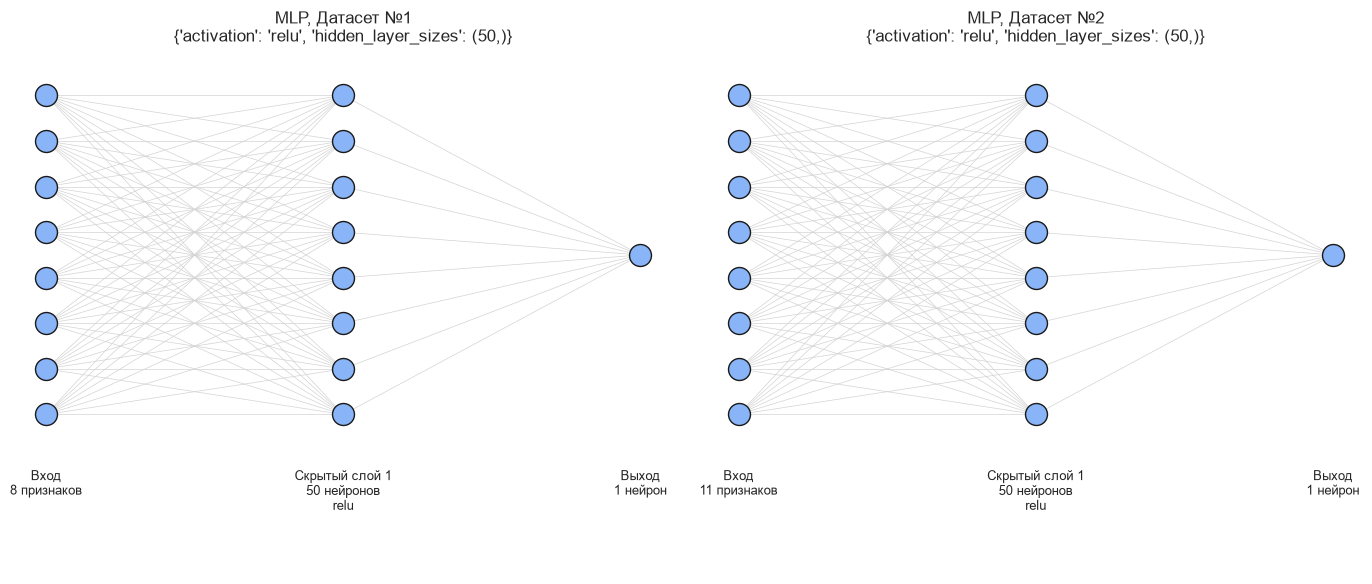

In [32]:
# MLP: схема сети с лучшей архитектурой (на схеме не более 8 нейронов в слое)
def plot_mlp(ax, grid, n_features, title, max_nodes=8):
    model = grid.best_estimator_
    hidden = list(model.hidden_layer_sizes)    # нейроны в скрытых слоях, например [50] или [50, 50]
    sizes = [n_features] + hidden + [1]        # размеры всех слоёв: вход, скрытые, выход (1 нейрон)

    # подписи под каждым слоем
    labels = [f"Вход\n{n_features} признаков"]
    labels += [f"Скрытый слой {i + 1}\n{n} нейронов\n{model.activation}" for i, n in enumerate(hidden)]
    labels += ["Выход\n1 нейрон"]

    # координаты нейронов: слой номер x стоит в точке x, нейроны расставлены по вертикали симметрично
    layers = []
    for x, n in enumerate(sizes):
        shown = min(n, max_nodes)    # рисуем не больше max_nodes нейронов, иначе схема нечитаема
        layers.append([(x, y) for y in np.linspace(-(shown - 1) / 2, (shown - 1) / 2, shown)])

    # связи: каждый нейрон слоя соединён линией с каждым нейроном следующего слоя
    for left, right in zip(layers[:-1], layers[1:]):
        for x1, y1 in left:
            for x2, y2 in right:
                ax.plot([x1, x2], [y1, y2], color='lightgray', linewidth=0.5, zorder=1)

    # сами нейроны (кружки) поверх линий и подпись каждого слоя снизу
    for x, layer in enumerate(layers):
        ax.scatter(*zip(*layer), s=250, color='#8ab4f8', edgecolor='k', zorder=2)
        ax.text(x, -(max_nodes - 1) / 2 - 1.2, labels[x], ha='center', va='top', fontsize=9)

    ax.set_ylim(-(max_nodes - 1) / 2 - 3.5, (max_nodes - 1) / 2 + 1)    # место под подписи
    ax.set_title(f"{title}\n{grid.best_params_}")                        # заголовок с лучшими параметрами
    ax.axis('off')                                                       # убираем оси, нужна только схема

# два графика рядом: слева датасет №1, справа датасет №2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_mlp(axes[0], grids1['MLP'], X_train1.shape[1], 'MLP, Датасет №1')
plot_mlp(axes[1], grids2['MLP'], X_train2.shape[1], 'MLP, Датасет №2')
plt.tight_layout()
plt.show()

## Часть 3. Оценка качества и сравнительный анализ

Для каждой оптимизированной модели на тестовой выборке выводим `Classification Report` (Accuracy, Precision, Recall, F1-score), строим матрицу неточностей и сводим метрики в таблицу.

In [33]:
def evaluate_models(grids, X_test, y_test, class_names):
    results = [] 
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))    # сетка 2x2: по одной матрице ошибок на модель

    # перебираем графики и модели одновременно: axes.ravel() превращает таблицу 2x2 в ряд из 4 графиков
    for ax, (name, grid) in zip(axes.ravel(), grids.items()):
        # лучшая модель (после подбора параметров) предсказывает классы для тестовой выборки
        pred = grid.best_estimator_.predict(X_test)

        print(f"{name}")
        print(classification_report(y_test, pred, target_names=class_names))

        sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=class_names, yticklabels=class_names, ax=ax)
        ax.set_title(name)
        ax.set_xlabel('Предсказанный класс')
        ax.set_ylabel('Истинный класс')

        # метрики для таблицы (считаются для класса "1": диабет / клиент ушёл)
        results.append({
            'Model': name,
            'Best parameters': grid.best_params_,
            'Accuracy': accuracy_score(y_test, pred),     # доля верных ответов
            'Precision': precision_score(y_test, pred),   # из предсказанных "1" сколько действительно "1"
            'Recall': recall_score(y_test, pred),         # из настоящих "1" сколько модель нашла
            'F1': f1_score(y_test, pred)                  # среднее между precision и recall
        })

    plt.tight_layout()
    plt.show()
    return pd.DataFrame(results)    # список словарей превращаем в таблицу pandas

### Датасет №1. Результаты

kNN
              precision    recall  f1-score   support

 Нет диабета       0.78      0.82      0.80       100
      Диабет       0.63      0.57      0.60        54

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154

Decision Tree
              precision    recall  f1-score   support

 Нет диабета       0.70      0.92      0.79       100
      Диабет       0.64      0.26      0.37        54

    accuracy                           0.69       154
   macro avg       0.67      0.59      0.58       154
weighted avg       0.68      0.69      0.64       154

SVM
              precision    recall  f1-score   support

 Нет диабета       0.75      0.83      0.79       100
      Диабет       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.66       154
weighted avg       0.70      0.71      0.70       15

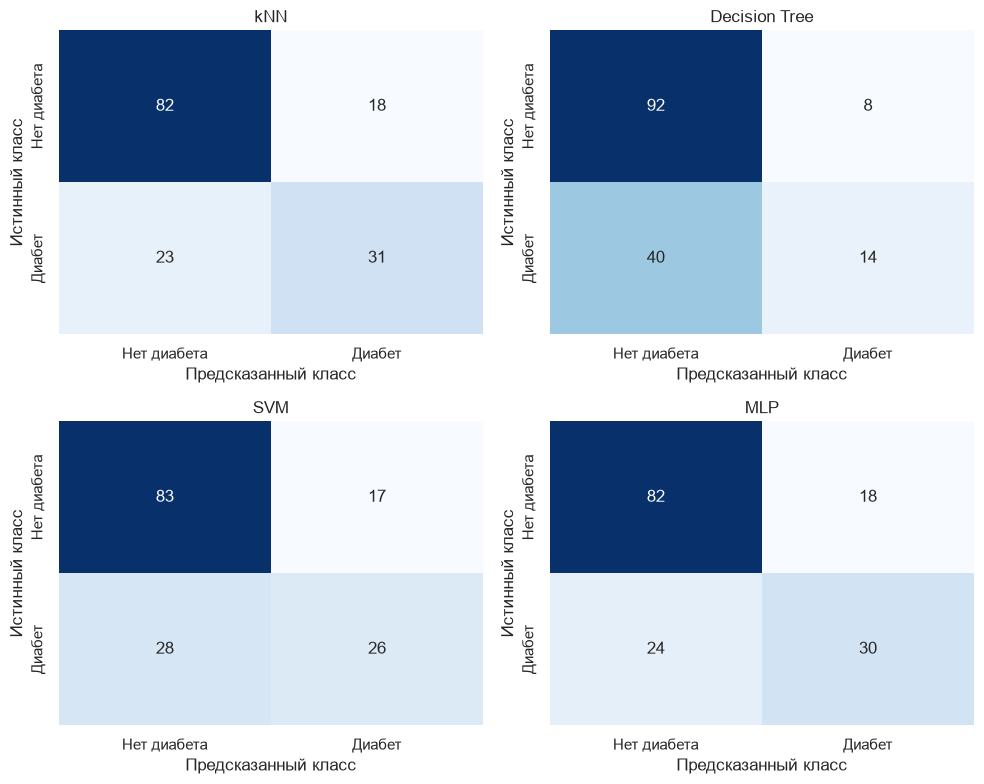

In [34]:
table1 = evaluate_models(grids1, X_test1, y_test1, class_names1)

In [35]:
print("Сравнительная таблица метрик (Датасет №1)")
display(table1.round(4))

Сравнительная таблица метрик (Датасет №1)


,Model,Best parameters,Accuracy,Precision,Recall,F1
0,kNN,{'n_neighbors': 11},0.7338,0.6327,0.5741,0.6019
1,Decision Tree,{'max_depth': 3},0.6883,0.6364,0.2593,0.3684
2,SVM,"{'C': 0.1, 'kernel': 'linear'}",0.7078,0.6047,0.4815,0.5361
3,MLP,"{'activation': 'relu', 'hidden_layer_sizes': (...",0.7273,0.6250,0.5556,0.5882


### Датасет №2. Результаты

kNN
              precision    recall  f1-score   support

     Остался       0.85      0.96      0.90      1593
        Ушёл       0.70      0.32      0.44       407

    accuracy                           0.83      2000
   macro avg       0.77      0.64      0.67      2000
weighted avg       0.82      0.83      0.81      2000

Decision Tree
              precision    recall  f1-score   support

     Остался       0.86      0.97      0.91      1593
        Ушёл       0.79      0.40      0.53       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.72      2000
weighted avg       0.85      0.86      0.84      2000

SVM
              precision    recall  f1-score   support

     Остался       0.86      0.98      0.92      1593
        Ушёл       0.83      0.40      0.54       407

    accuracy                           0.86      2000
   macro avg       0.85      0.69      0.73      2000
weighted avg       0.86      0.86      0.84      200

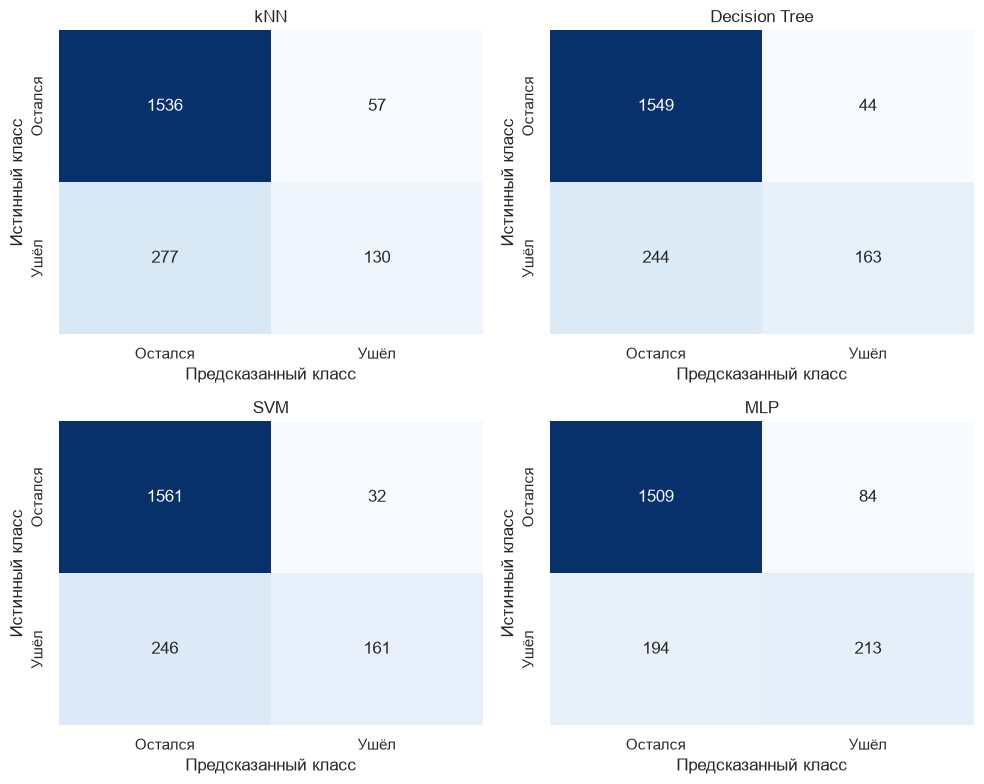

In [36]:
table2 = evaluate_models(grids2, X_test2, y_test2, class_names2)

In [37]:
print("Сравнительная таблица метрик (Датасет №2)")
display(table2.round(4))

Сравнительная таблица метрик (Датасет №2)


,Model,Best parameters,Accuracy,Precision,Recall,F1
0,kNN,{'n_neighbors': 9},0.833,0.6952,0.3194,0.4377
1,Decision Tree,{'max_depth': 5},0.856,0.7874,0.4005,0.5309
2,SVM,"{'C': 1, 'kernel': 'rbf'}",0.861,0.8342,0.3956,0.5367
3,MLP,"{'activation': 'relu', 'hidden_layer_sizes': (...",0.861,0.7172,0.5233,0.6051


### Вывод

В работе четыре алгоритма классификации (kNN, Decision Tree, SVM, MLP) сравнены на двух наборах данных. Гиперпараметры подобраны через `GridSearchCV`.

**Лучшие гиперпараметры**

| Алгоритм | Датасет №1 (диабет) | Датасет №2 (отток) |
|---|---|---|
| kNN | 11 соседей | 9 соседей |
| Decision Tree | глубина 3 | глубина 5 |
| SVM | `C=1`, ядро `linear` | `C=1`, ядро `rbf` |
| MLP | 1 слой (50), `relu` | 1 слой (50), `relu` |

**Датасет №1: диабет (768 объектов, около 35% больных)**
* Accuracy всех моделей 0.69–0.73, что близко к доле здоровых (0.65), поэтому по ней модели сравнивать нельзя.
* Лучшая модель: **MLP** (F1 = 0.598, Recall = 0.593): нашёл 32 из 54 больных.
* kNN имеет наибольшую Accuracy (0.727), но пропустил 24 больных.
* Худшая модель: **Decision Tree**, Recall всего 0.259 (нашёл 14 из 54 больных).

**Датасет №2: отток клиентов (10 000 объектов, около 20% ушедших)**
* Accuracy 0.83–0.86 при доле оставшихся 0.80, поэтому по ней тоже нельзя судить о качестве.
* Лучшая модель: **MLP** (F1 = 0.605, Recall = 0.523): нашёл 213 из 407 уходящих клиентов.
* kNN, Decision Tree и SVM находят не более 40% уходящих клиентов (Recall ≤ 0.40).
* SVM и Decision Tree имеют высокий Precision (0.834 и 0.787): они реже ошибаются, но пропускают больше клиентов.
* Худшая модель: **kNN** (F1 = 0.438).

**Итог**
* При несбалансированных классах Accuracy завышает качество, поэтому модели сравниваются по Recall и F1.
* По этим метрикам лучшая модель на обоих датасетах: **MLP**.
* Если важнее меньше ложных тревог, подходит **SVM** (наибольший Precision на втором датасете).